# EXPERIMENT - 6 

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Loading the dataset
df = pd.read_csv('USA_Housing.csv')

In [4]:
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386


In [5]:
df.shape

(5000, 7)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Avg. Area Income              5000 non-null   float64
 1   Avg. Area House Age           5000 non-null   float64
 2   Avg. Area Number of Rooms     5000 non-null   float64
 3   Avg. Area Number of Bedrooms  5000 non-null   float64
 4   Area Population               5000 non-null   float64
 5   Price                         5000 non-null   float64
 6   Address                       5000 non-null   object 
dtypes: float64(6), object(1)
memory usage: 273.6+ KB


<Axes: title={'center': 'Price'}, xlabel='Price'>

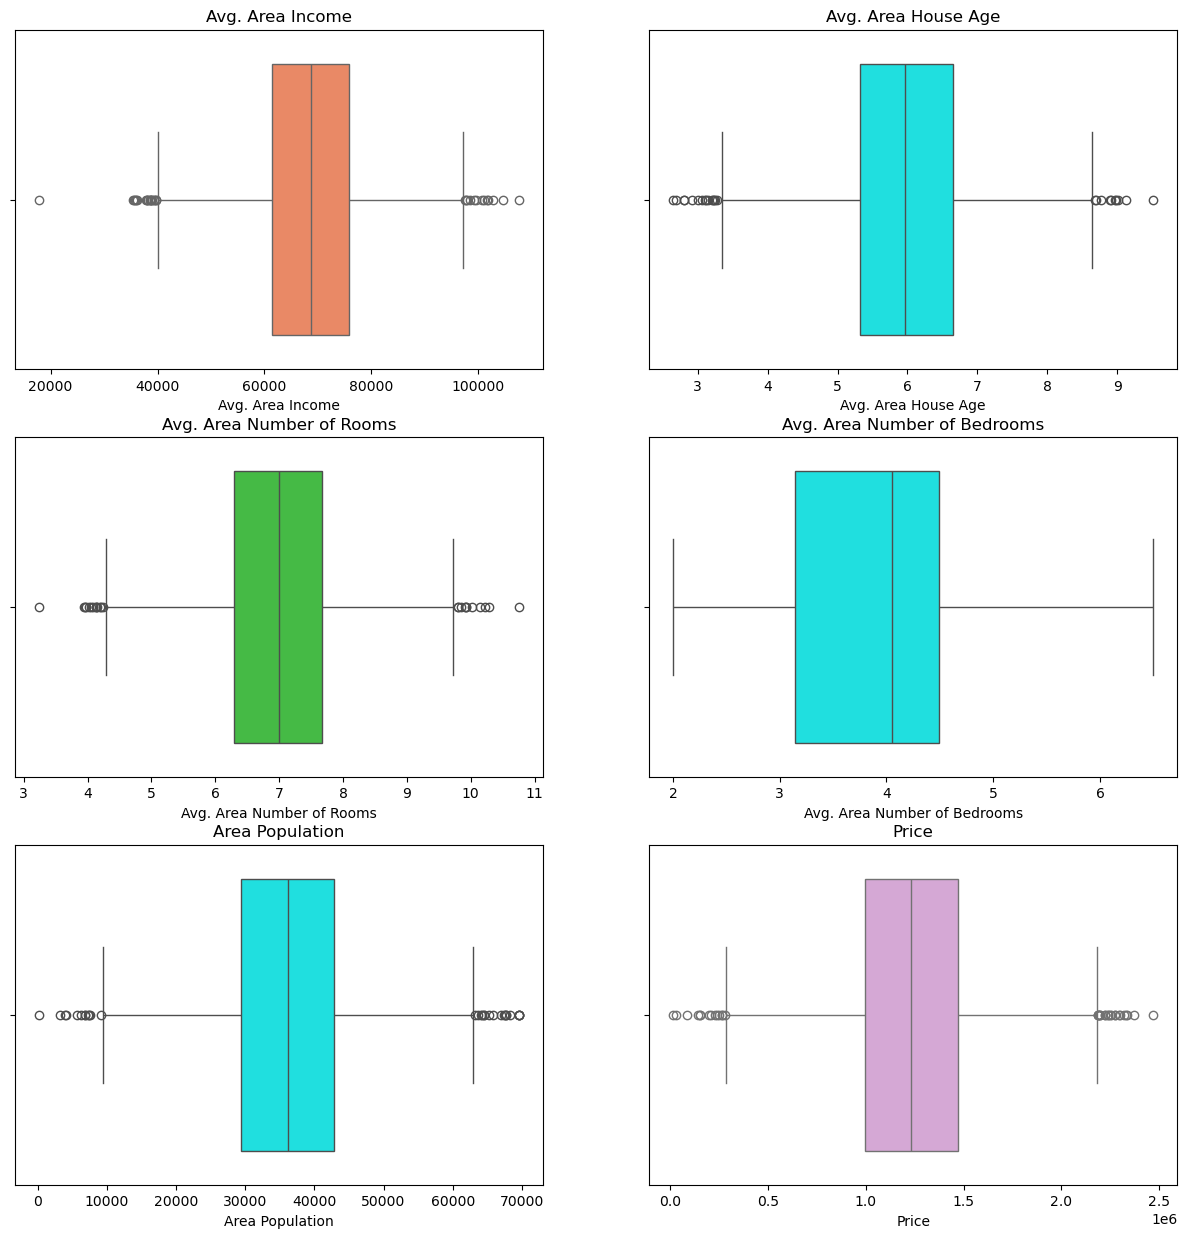

In [14]:
plt.figure(figsize=(15,15))

plt.subplot(3,2,1)
plt.title('Avg. Area Income')
sns.boxplot(df['Avg. Area Income'],orient="h",color='coral')

plt.subplot(3,2,2)
plt.title('Avg. Area House Age')
sns.boxplot(df['Avg. Area House Age'],orient="h",color='aqua')

plt.subplot(3,2,3)
plt.title('Avg. Area Number of Rooms')
sns.boxplot(df['Avg. Area Number of Rooms'],orient="h", color='limegreen')

plt.subplot(3,2,4)
plt.title('Avg. Area Number of Bedrooms')
sns.boxplot(df['Avg. Area Number of Bedrooms'], orient="h", color='aqua')

plt.subplot(3,2,5)
plt.title('Area Population')
sns.boxplot(df['Area Population'],orient="h",color='aqua')

plt.subplot(3,2,6)
plt.title('Price')
sns.boxplot(df['Price'],orient="h",color='plum')




In [15]:
new_df = df
new_df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386


In [17]:
col_list = ['Avg. Area Income', 'Avg. Area House Age','Avg. Area Number of Rooms','Area Population', 'Price']
print(type(col_list))
for i in col_list:
    print(i)

<class 'list'>
Avg. Area Income
Avg. Area House Age
Avg. Area Number of Rooms
Area Population
Price


In [21]:
for item in col_list:
    q1 = new_df[item].quantile(0.25)
    q3 = new_df[item].quantile(0.75)
    IQR = q3 - q1
    lower_limit = q1 - 1.5*IQR
    upper_limit = q3 + 1.5*IQR
    upper_array = np.where(new_df[item] >= upper_limit) [0]
    lower_array = np.where(new_df[item] <= lower_limit) [0]
    new_df.drop(index=upper_array, inplace=True)
    new_df.drop(index=lower_array, inplace=True)
    new_df.reset_index(inplace=True, drop=True)
    print("Outliers removed from Column: ",item, "New shape: ",new_df.shape)

Outliers removed from Column:  Avg. Area Income New shape:  (4843, 7)
Outliers removed from Column:  Avg. Area House Age New shape:  (4843, 7)
Outliers removed from Column:  Avg. Area Number of Rooms New shape:  (4842, 7)
Outliers removed from Column:  Area Population New shape:  (4842, 7)
Outliers removed from Column:  Price New shape:  (4839, 7)


In [22]:
new_df.shape

(4839, 7)

In [23]:
new_df = new_df.drop(columns="Address")
new_df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05


In [25]:
x = new_df.drop(columns='Price') 
y = new_df['Price']

In [26]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
sc_x = sc.fit_transform(x)
print(sc_x)

[[ 1.06860701 -0.30764845  0.02314752  0.08411262 -1.35375174]
 [ 1.03955609  0.02447525 -0.26053235 -0.72573428  0.42166251]
 [-0.71843579 -0.11770845  1.55538247  0.92635338  0.07970766]
 ...
 [-0.5125437   1.31928107 -2.22302593 -1.50318729 -0.29602806]
 [-0.06127619 -0.46172796  0.14641173  1.17740592  0.67650386]
 [-0.30505866  0.01348068 -0.19784323  0.06791568  1.07921948]]


In [28]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(sc_x,y,test_size=0.2,random_state=5)

In [54]:
from sklearn.linear_model import LinearRegression

model= LinearRegression()


model.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [55]:
coefficients = model.coef_
print(coefficients)

[219528.36227144 158554.61793139 117596.72720132   4186.55431034
 143776.20994748]


In [56]:
intercept = model.intercept_
print(intercept)

1232809.7996745221


In [35]:
y_price_predicted = model.predict(x_test) # predict
y_price_predicted

array([ 729166.54298339, 1504145.90745525, 1490136.42046169,
       1124927.51550161, 1752622.59977969, 1177184.54533805,
       1555825.71444484, 1362833.87526514, 1709997.8242473 ,
       1173099.99201305, 1475196.4133782 ,  949582.94321363,
       1378282.93122253, 1895181.99428714, 1050868.32168834,
        766892.44257978, 1287815.27816956,  896253.44027328,
       1064946.46057693, 1020328.66751046, 1138227.40133714,
       1784512.04461334, 1257264.55272457, 1808120.76793448,
       1272769.30403281, 1615536.91381391, 1352802.29287826,
       1267540.20304806, 1457732.58367528, 1398699.33993662,
       1238042.49582928, 1380778.97114691, 1098084.67870321,
       1769919.85599088, 1790906.13891466,  932808.4674051 ,
       1142509.04850902, 1361044.34995691, 1894324.80018908,
        778154.11865749,  799053.87061814, 1487637.10679594,
        571423.19024242, 1552624.78726932, 1346776.88768712,
       1266817.13163528, 1210829.293737  ,  680967.37297966,
        983497.15252194,

In [37]:
import statsmodels.api as sm

In [39]:
x_cols = new_df[['Avg. Area Income', 'Avg. Area House Age','Avg. Area Number of Rooms','Avg. Area Number of Bedrooms','Area Population']]

y_col = new_df['Price']
x_cols = sm.add_constant(x_cols)
model = sm.OLS(y_col, x_cols).fit()


print("Adjusted R^2: ",model.rsquared_adj)

Adjusted R^2:  0.9096305127924975


In [43]:
result_table = pd.DataFrame({'Actual value': y_test,'Predicted value': y_price_predicted,'Error':(y_test- y_price_predicted)/300000})

result_table.head()

,Actual value,Predicted value,Error
2845,5.781615e+05,7.291665e+05,-0.503350
1903,1.417691e+06,1.504146e+06,-0.288183
177,1.494125e+06,1.490136e+06,0.013296
4513,9.060114e+05,1.124928e+06,-0.729720
994,1.726364e+06,1.752623e+06,-0.087527


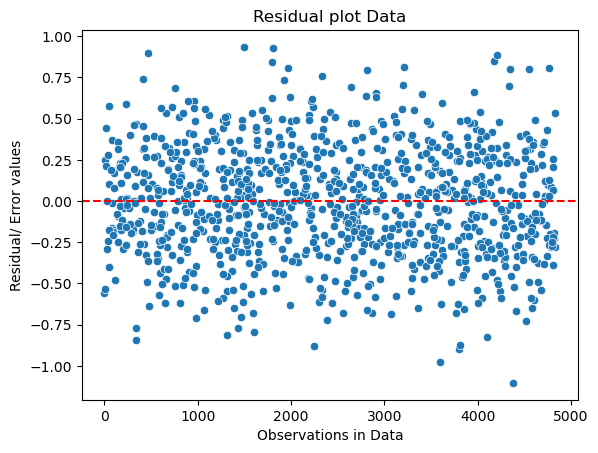

In [48]:
sns.scatterplot(result_table['Error'])
plt.title('Residual plot Data')
plt.xlabel('Observations in Data')
plt.ylabel('Residual/ Error values')
plt.axhline(y=0, linestyle='--',color='red')
plt.show()

In [57]:
# conclusion -
#-R^2=0.9096
#-intercet is -1232809.7996745221
#-this graph does not make any pattern hence it is perfect for regression 
- in todays lab we learned multiple regression

SyntaxError: cannot assign to expression here. Maybe you meant '==' instead of '='? (2377076074.py, line 2)